In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [23]:
df = pd.read_excel('/content/dataset.xlsx')
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [24]:
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (9568, 5)

First five rows:


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90



Column names:
['AT', 'V', 'AP', 'RH', 'PE']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB

Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Statistical summary:


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


In [25]:
X = df[['AT','V','AP', 'RH']]
Y = df['PE']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print ("Training samples:",len(X_train))
print ("Testing samples:",len(X_test))


Training samples: 7654
Testing samples: 1914


Regression model : MAE,MSE,Huber loss

In [26]:
model=LinearRegression()
model.fit(X_train,Y_train)

Y_pred = model.predict(X_test)

In [27]:
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)

print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 4))

MAE: 3.596
MSE: 20.274
RMSE: 4.503
R2 Score: 0.9301


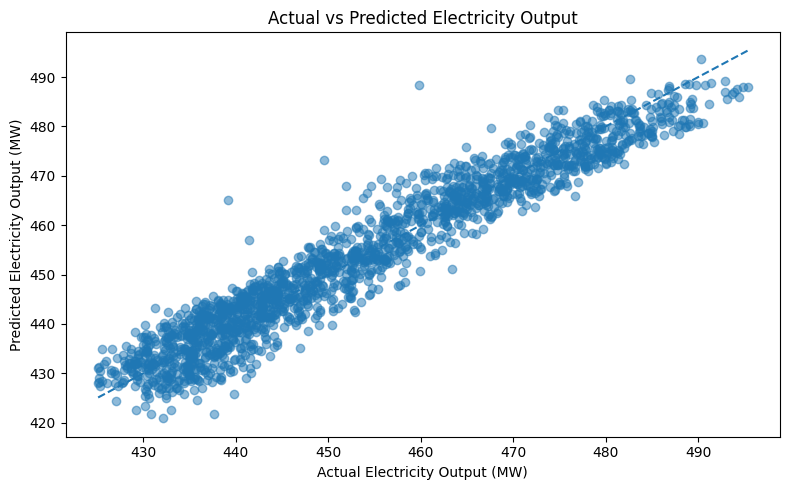

In [28]:
plt.figure(figsize=(8, 5))
plt.scatter(Y_test, Y_pred, alpha=0.5)

plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Electricity Output (MW)")
plt.ylabel("Predicted Electricity Output (MW)")
plt.title("Actual vs Predicted Electricity Output")

plt.tight_layout()
plt.show()

In [29]:
Y_train_outliers = Y_train.copy()

np.random.seed(42)

n_outliers = int(0.05 * len(Y_train_outliers))

outlier_indices = np.random.choice(
    len(Y_train_outliers),
    size=n_outliers,
    replace=False
)

Y_train_outliers.iloc[outlier_indices] += np.random.choice(
    [-1, 1],
    size=n_outliers
) * 50

print("Original training observations:", len(Y_train))
print("Artificial outliers introduced:", n_outliers)
print("Original target mean:", round(Y_train.mean(), 2))
print("Modified target mean:", round(Y_train_outliers.mean(), 2))

Original training observations: 7654
Artificial outliers introduced: 382
Original target mean: 454.43
Modified target mean: 454.43


In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import QuantileRegressor
from sklearn.linear_model import HuberRegressor

model_mse = LinearRegression()
model_mse.fit(X_train, Y_train_outliers)

model_mae = QuantileRegressor(
    quantile=0.5,
    alpha=0
)
model_mae.fit(X_train, Y_train_outliers)

model_huber = HuberRegressor(
    epsilon=1.35,
    max_iter=1000
)
model_huber.fit(X_train, Y_train_outliers)

print("All three models trained successfully!")

All three models trained successfully!


In [31]:
models = {
    "MSE - Linear Regression": model_mse,
    "MAE - Quantile Regression": model_mae,
    "Huber Regression": model_huber
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(Y_test, predictions),
        "MSE": mean_squared_error(Y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(Y_test, predictions)),
        "R2": r2_score(Y_test, predictions)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2
0,MSE - Linear Regression,3.6120,20.2915,4.5046,0.9300
1,MAE - Quantile Regression,3.6008,20.5953,4.5382,0.9290
2,Huber Regression,3.9753,24.9794,4.9979,0.9139


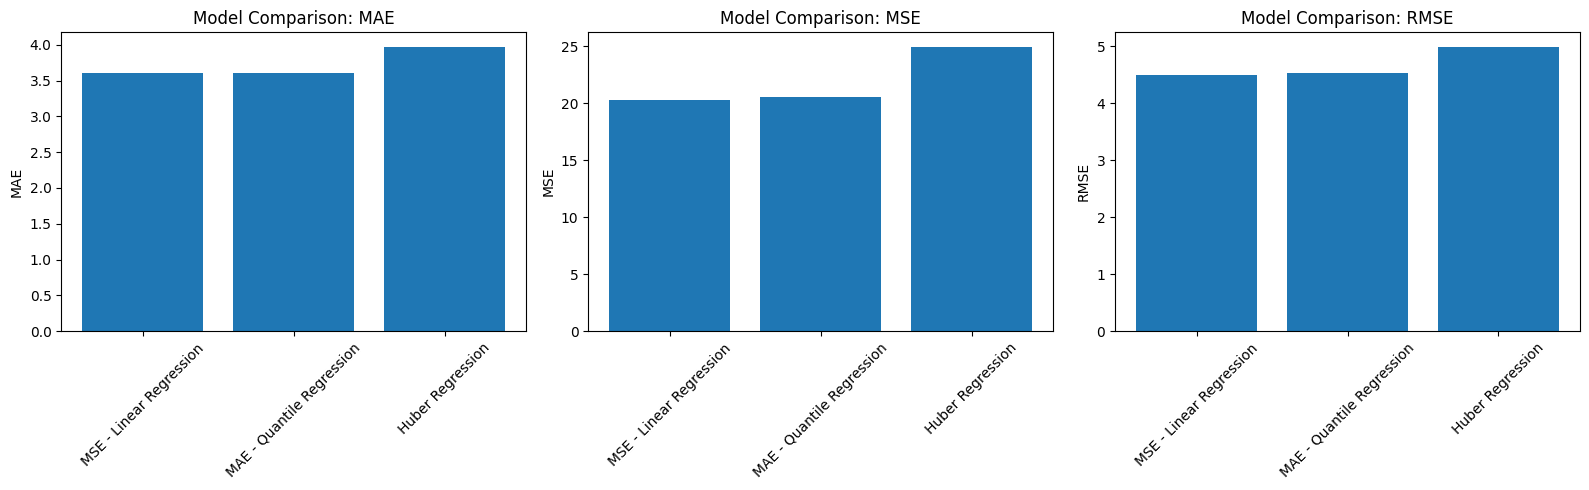

In [32]:
metrics = ["MAE", "MSE", "RMSE"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, metrics):
    ax.bar(results_df["Model"], results_df[metric])
    ax.set_title(f"Model Comparison: {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

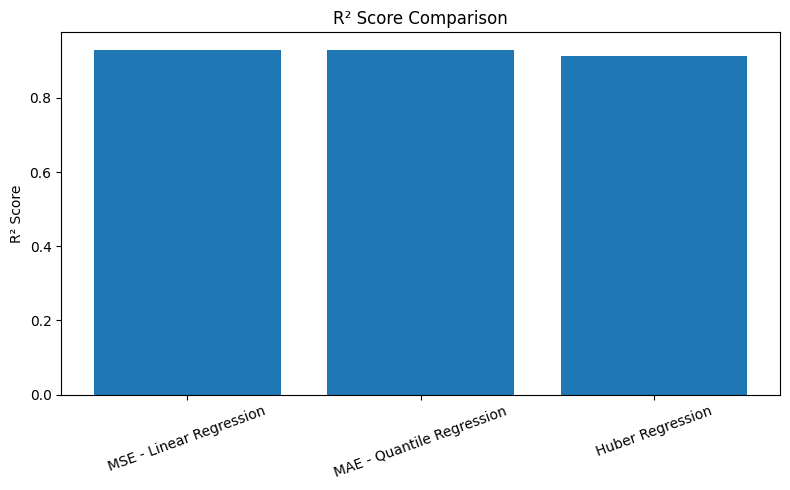

In [33]:
plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["R2"])

plt.title("R² Score Comparison")
plt.ylabel("R² Score")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [34]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, QuantileRegressor, HuberRegressor

model_configs = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Quantile Regression": make_pipeline(
        StandardScaler(),
        QuantileRegressor(quantile=0.5, alpha=0)
    ),
    "Huber Regression": make_pipeline(
        StandardScaler(),
        HuberRegressor(epsilon=1.35, alpha=0.0001, max_iter=1000)
    )
}

contamination_levels = [0, 0.05, 0.10]
sensitivity_results = []

for level in contamination_levels:
    Y_train_modified = Y_train.copy()

    rng = np.random.default_rng(42)
    n_outliers = int(level * len(Y_train_modified))

    if n_outliers > 0:
        indices = rng.choice(
            len(Y_train_modified),
            size=n_outliers,
            replace=False
        )

        noise = rng.choice([-50, 50], size=n_outliers)
        Y_train_modified.iloc[indices] += noise

    for name, estimator in model_configs.items():
        model = clone(estimator)
        model.fit(X_train, Y_train_modified)

        predictions = model.predict(X_test)

        sensitivity_results.append({
            "Outlier Percentage": f"{int(level * 100)}%",
            "Model": name,
            "MAE": mean_absolute_error(Y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(Y_test, predictions)),
            "R2": r2_score(Y_test, predictions)
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))

,Outlier Percentage,Model,MAE,RMSE,R2
0,0%,Linear Regression,3.5959,4.5026,0.9301
1,0%,Quantile Regression,3.5998,4.5358,0.9291
2,0%,Huber Regression,3.5951,4.5255,0.9294
3,5%,Linear Regression,3.6075,4.5047,0.9300
4,5%,Quantile Regression,3.5992,4.5348,0.9291
5,5%,Huber Regression,3.5941,4.5213,0.9295
6,10%,Linear Regression,3.6010,4.5237,0.9294
7,10%,Quantile Regression,3.6013,4.5423,0.9289
8,10%,Huber Regression,3.5958,4.5282,0.9293


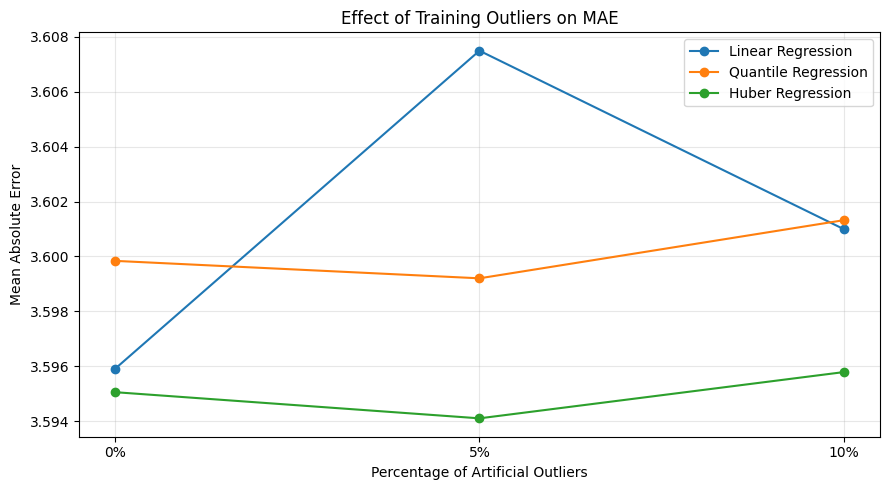

In [35]:
plt.figure(figsize=(9, 5))

for model_name in sensitivity_df["Model"].unique():
    subset = sensitivity_df[sensitivity_df["Model"] == model_name]

    plt.plot(
        subset["Outlier Percentage"],
        subset["MAE"],
        marker="o",
        label=model_name
    )

plt.title("Effect of Training Outliers on MAE")
plt.xlabel("Percentage of Artificial Outliers")
plt.ylabel("Mean Absolute Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

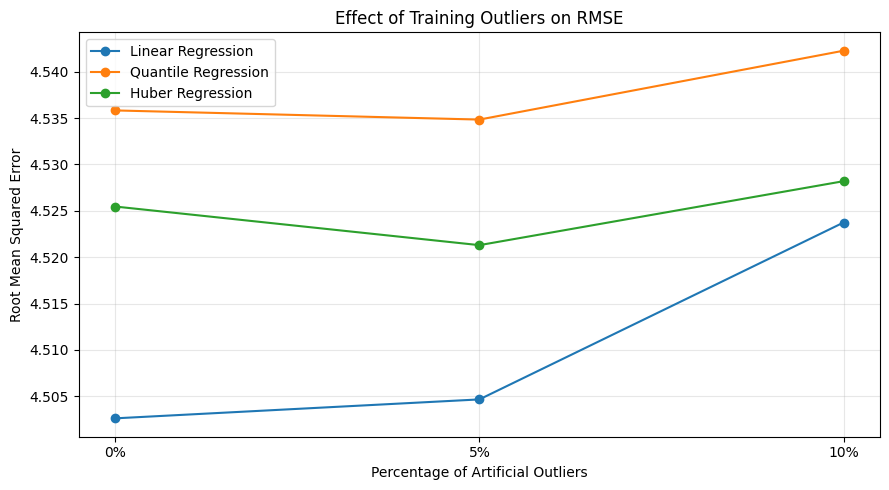

In [36]:
plt.figure(figsize=(9, 5))

for model_name in sensitivity_df["Model"].unique():
    subset = sensitivity_df[sensitivity_df["Model"] == model_name]

    plt.plot(
        subset["Outlier Percentage"],
        subset["RMSE"],
        marker="o",
        label=model_name
    )

plt.title("Effect of Training Outliers on RMSE")
plt.xlabel("Percentage of Artificial Outliers")
plt.ylabel("Root Mean Squared Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

classification - binary vs categorial entropy


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
data = load_breast_cancer()
X=data.data
y=data.target
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(
    y_train.reshape(-1, 1),
    dtype=torch.float32
)

y_val_t = torch.tensor(
    y_val.reshape(-1, 1),
    dtype=torch.float32
)

y_test_t = torch.tensor(
    y_test.reshape(-1, 1),
    dtype=torch.float32
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 364
Validation samples: 91
Testing samples: 114


In [38]:
torch.manual_seed(42)

class BinaryClassifier(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


model_binary = BinaryClassifier(X_train.shape[1])

criterion_binary = nn.BCEWithLogitsLoss()

optimizer_binary = torch.optim.Adam(
    model_binary.parameters(),
    lr=0.001
)

epochs = 100
train_losses = []
validation_losses = []

for epoch in range(epochs):
    model_binary.train()

    optimizer_binary.zero_grad()

    train_logits = model_binary(X_train_t)
    train_loss = criterion_binary(train_logits, y_train_t)

    train_loss.backward()
    optimizer_binary.step()

    model_binary.eval()

    with torch.no_grad():
      validation_logits = model_binary(X_val_t)

      validation_loss = criterion_binary(
        validation_logits,
        y_val_t
)
    train_losses.append(train_loss.item())
    validation_losses.append(validation_loss.item())

print("Training completed!")
print("Final training loss:", round(train_losses[-1], 4))
print("Final validation loss:", round(validation_losses[-1], 4))

Training completed!
Final training loss: 0.1133
Final validation loss: 0.122


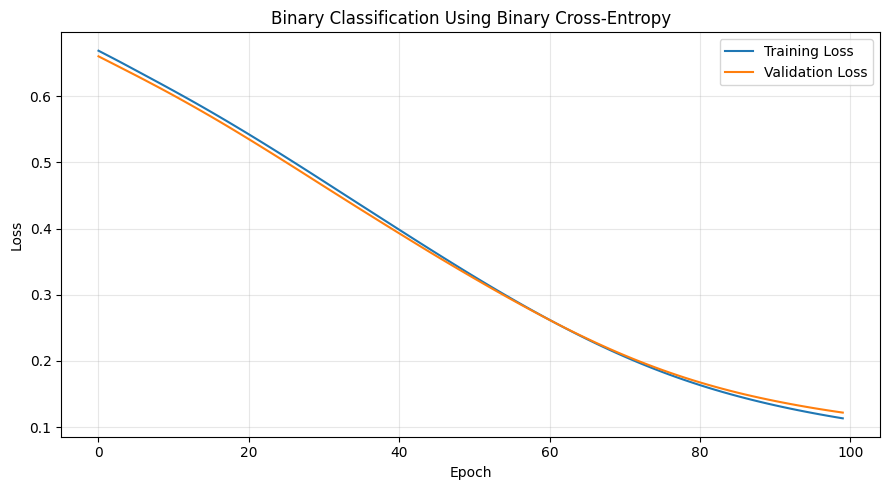

In [39]:
plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(validation_losses, label="Validation Loss")

plt.title("Binary Classification Using Binary Cross-Entropy")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
model_binary.eval()

with torch.no_grad():
    logits = model_binary(X_test_t)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).int().numpy().ravel()

print("Accuracy:", round(accuracy_score(y_test_t, predictions), 4))
print("Precision:", round(precision_score(y_test_t, predictions), 4))
print("Recall:", round(recall_score(y_test_t, predictions), 4))
print("F1 Score:", round(f1_score(y_test_t, predictions), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_t,
        predictions,
        target_names=data.target_names
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test_t, predictions))

Accuracy: 0.9561
Precision: 0.9589
Recall: 0.9722
F1 Score: 0.9655

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Confusion Matrix:
[[39  3]
 [ 2 70]]


Multiple class entropy (categorial)

In [41]:
from sklearn.datasets import load_digits

digits = load_digits()
X_multi= digits.data
y_multi=digits.target
X_train_full_m, X_test_m, y_train_full_m, y_test_m = train_test_split(
    X_multi,
    y_multi,
    test_size=0.2,
    random_state=42,
    stratify=y_multi
)

X_train_m, X_val_m, y_train_m, y_val_m = train_test_split(
    X_train_full_m,
    y_train_full_m,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full_m
)

scaler_multi = StandardScaler()

X_train_m = scaler_multi.fit_transform(X_train_m)
X_val_m = scaler_multi.transform(X_val_m)
X_test_m = scaler_multi.transform(X_test_m)

X_train_m_t = torch.tensor(X_train_m, dtype=torch.float32)
X_val_m_t = torch.tensor(X_val_m, dtype=torch.float32)
X_test_m_t = torch.tensor(X_test_m, dtype=torch.float32)

y_train_m_t = torch.tensor(y_train_m, dtype=torch.long)
y_val_m_t = torch.tensor(y_val_m, dtype=torch.long)
y_test_m_t = torch.tensor(y_test_m, dtype=torch.long)

print("Training samples:", len(X_train_m))
print("Validation samples:", len(X_val_m))
print("Testing samples:", len(X_test_m))
print("Number of classes:", len(np.unique(y_multi)))

Training samples: 1149
Validation samples: 288
Testing samples: 360
Number of classes: 10


In [42]:
torch.manual_seed(42)

class MultiClassClassifier(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


model_multi = MultiClassClassifier(
    X_train_m.shape[1],
    len(np.unique(y_multi))
)

criterion_multi = nn.CrossEntropyLoss()

optimizer_multi = torch.optim.Adam(
    model_multi.parameters(),
    lr=0.001
)

epochs_multi = 100
train_losses_multi = []
validation_losses_multi = []

for epoch in range(epochs_multi):
    model_multi.train()

    optimizer_multi.zero_grad()

    train_logits = model_multi(X_train_m_t)
    train_loss = criterion_multi(train_logits, y_train_m_t)

    train_loss.backward()
    optimizer_multi.step()

    model_multi.eval()

    with torch.no_grad():
        validation_logits = model_multi(X_val_m_t)

        validation_loss = criterion_multi(
          validation_logits,
          y_val_m_t
)

    train_losses_multi.append(train_loss.item())
    validation_losses_multi.append(validation_loss.item())

print("Training completed!")
print("Final training loss:", round(train_losses_multi[-1], 4))
print("Final validation loss:", round(validation_losses_multi[-1], 4))

Training completed!
Final training loss: 0.2131
Final validation loss: 0.2369


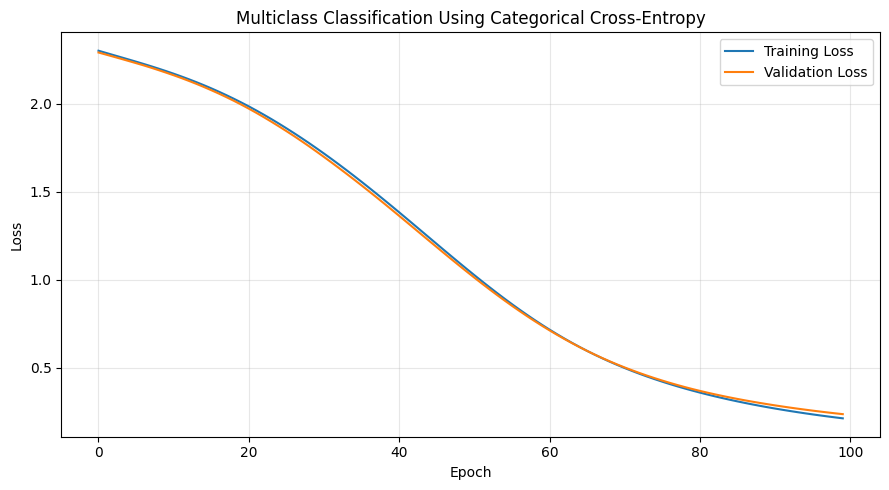

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(train_losses_multi, label="Training Loss")
plt.plot(validation_losses_multi, label="Validation Loss")

plt.title("Multiclass Classification Using Categorical Cross-Entropy")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
model_multi.eval()

with torch.no_grad():
    logits_multi = model_multi(X_test_m_t)

    predictions_multi = torch.argmax(
        logits_multi,
        dim=1
    ).numpy()

print(
    "Accuracy:",
    round(accuracy_score(y_test_m_t, predictions_multi), 4))
print(
    "Macro F1 Score:",
    round(f1_score(y_test_m_t,predictions_multi, average="macro"),4))

print("\nClassification Report:")
print(classification_report(y_test_m_t, predictions_multi))

Accuracy: 0.9361
Macro F1 Score: 0.9342

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.83      0.94      0.88        36
           2       0.97      0.97      0.97        35
           3       0.92      0.95      0.93        37
           4       0.92      0.97      0.95        36
           5       0.97      0.97      0.97        37
           6       0.97      0.97      0.97        36
           7       0.90      1.00      0.95        36
           8       0.96      0.69      0.80        35
           9       0.94      0.92      0.93        36

    accuracy                           0.94       360
   macro avg       0.94      0.94      0.93       360
weighted avg       0.94      0.94      0.93       360

